Week 12 – Automobile Pricing and Performance Trade-off Analysis

1.Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

2. Load the Week 11 cleaned dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [3]:
df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/automobile_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (205, 30)


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price,power_to_weight,combined_mpg,weight_category,engine_category
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,9.0,111.0,5000.0,21.0,27.0,13495.0,0.043564,24.0,Medium,Medium
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,9.0,111.0,5000.0,21.0,27.0,16500.0,0.043564,24.0,Medium,Medium
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,9.0,154.0,5000.0,19.0,26.0,16500.0,0.054552,22.5,Medium,Medium
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,10.0,102.0,5500.0,24.0,30.0,13950.0,0.043646,27.0,Medium,Medium
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,8.0,115.0,5500.0,18.0,22.0,17450.0,0.040722,20.0,Medium,Medium


3. Understand the dataset

In [4]:
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nMissing Values:")
display(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized_losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel_type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num_of_doors       205 non-null    object 
 6   body_style         205 non-null    object 
 7   drive_wheels       205 non-null    object 
 8   engine_location    205 non-null    object 
 9   wheel_base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb_weight        205 non-null    float64
 14  engine_type        205 non-null    object 
 15  num_of_cylinders   205 non-null    object 
 16  engin

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
symboling,205.0,NaN,NaN,NaN,0.834146,1.245307,-2.0,0.0,1.0,2.0,3.0
normalized_losses,205,52,?,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
make,205,22,toyota,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel_type,205,2,gas,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aspiration,205,2,std,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_of_doors,205,3,four,114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body_style,205,5,sedan,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
drive_wheels,205,3,fwd,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine_location,205,2,front,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wheel_base,205.0,NaN,NaN,NaN,98.756585,6.021776,86.6,94.5,97.0,102.4,120.9



Missing Values:


,0
symboling,0
normalized_losses,0
make,0
fuel_type,0
aspiration,0
num_of_doors,0
body_style,0
drive_wheels,0
engine_location,0
wheel_base,0


In [5]:
required_columns = [
    "make",
    "price",
    "horsepower",
    "engine_size",
    "curb_weight",
    "city_mpg",
    "highway_mpg",
    "power_to_weight",
    "combined_mpg"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

print("All required columns are available.")

All required columns are available.


4. Prepare data for analysis

In [6]:
numeric_columns = [
    "price",
    "horsepower",
    "engine_size",
    "curb_weight",
    "city_mpg",
    "highway_mpg",
    "power_to_weight",
    "combined_mpg"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df["make"] = df["make"].astype("string").str.strip()

df = df.dropna(
    subset=[
        "make",
        "price",
        "horsepower",
        "engine_size",
        "curb_weight",
        "city_mpg",
        "highway_mpg"
    ]
).copy()

df = df[
    (df["price"] > 0) &
    (df["horsepower"] > 0) &
    (df["engine_size"] > 0) &
    (df["curb_weight"] > 0) &
    (df["city_mpg"] > 0) &
    (df["highway_mpg"] > 0)
].copy()

# Recalculate engineered features for consistency
df["power_to_weight"] = (
    df["horsepower"] / df["curb_weight"]
)

df["combined_mpg"] = (
    df["city_mpg"] + df["highway_mpg"]
) / 2

print("Prepared dataset shape:", df.shape)

display(df.head())

Prepared dataset shape: (205, 30)


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,...,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price,power_to_weight,combined_mpg,weight_category,engine_category
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,9.0,111.0,5000.0,21.0,27.0,13495.0,0.043564,24.0,Medium,Medium
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,9.0,111.0,5000.0,21.0,27.0,16500.0,0.043564,24.0,Medium,Medium
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,9.0,154.0,5000.0,19.0,26.0,16500.0,0.054552,22.5,Medium,Medium
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,10.0,102.0,5500.0,24.0,30.0,13950.0,0.043646,27.0,Medium,Medium
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,8.0,115.0,5500.0,18.0,22.0,17450.0,0.040722,20.0,Medium,Medium


5. Automobile price analysis

5.1 Descriptive statistics of automobile prices

In [7]:
print("Automobile Price Statistics")

display(
    df["price"].describe().to_frame(
        name="Price Statistics"
    ).round(2)
)

print("\nMedian Price:", round(df["price"].median(), 2))
print("Average Price:", round(df["price"].mean(), 2))
print("Minimum Price:", round(df["price"].min(), 2))
print("Maximum Price:", round(df["price"].max(), 2))

Automobile Price Statistics


,Price Statistics
count,205.00
mean,13284.51
std,8010.02
min,5118.00
25%,7788.00
50%,10295.00
75%,16503.00
max,45400.00



Median Price: 10295.0
Average Price: 13284.51
Minimum Price: 5118.0
Maximum Price: 45400.0


5.2 Automobile price distribution

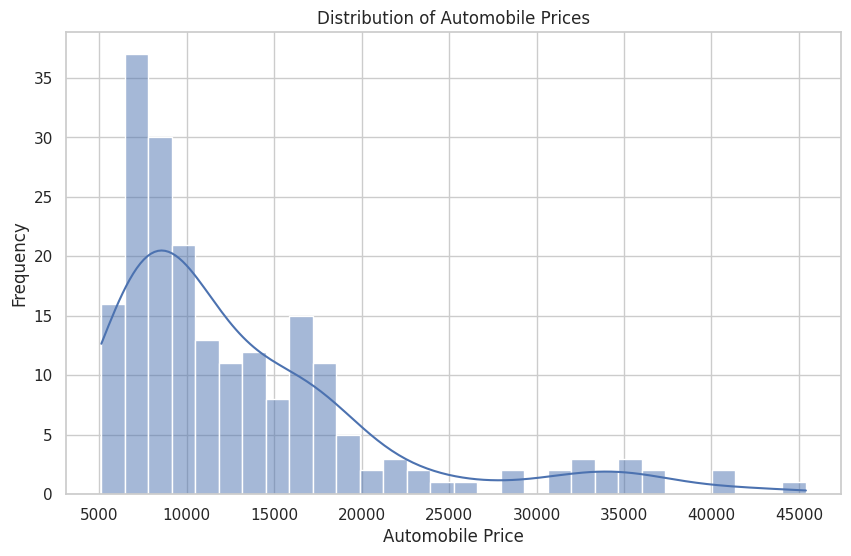

In [8]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="price",
    bins=30,
    kde=True
)

plt.title("Distribution of Automobile Prices")
plt.xlabel("Automobile Price")
plt.ylabel("Frequency")
plt.show()

5.3 Average price by manufacturer

In [9]:
manufacturer_price = (
    df.groupby("make")["price"]
    .agg(
        vehicle_count="count",
        average_price="mean",
        median_price="median",
        minimum_price="min",
        maximum_price="max"
    )
    .reset_index()
    .sort_values("average_price", ascending=False)
)

display(manufacturer_price.round(2))

,make,vehicle_count,average_price,median_price,minimum_price,maximum_price
7,jaguar,3,34600.00,35550.0,32250.0,36000.0
9,mercedes-benz,8,33647.00,32892.0,25552.0,45400.0
15,porsche,5,31776.00,33278.0,22018.0,37028.0
2,bmw,8,26118.75,22835.0,16430.0,41315.0
21,volvo,11,18063.18,18420.0,12940.0,22625.0
1,audi,7,17819.29,17580.0,13950.0,23875.0
10,mercury,1,16503.00,16503.0,16503.0,16503.0
0,alfa-romero,3,15498.33,16500.0,13495.0,16500.0
13,peugot,11,15489.09,16630.0,11900.0,18150.0
17,saab,6,15223.33,15275.0,11850.0,18620.0


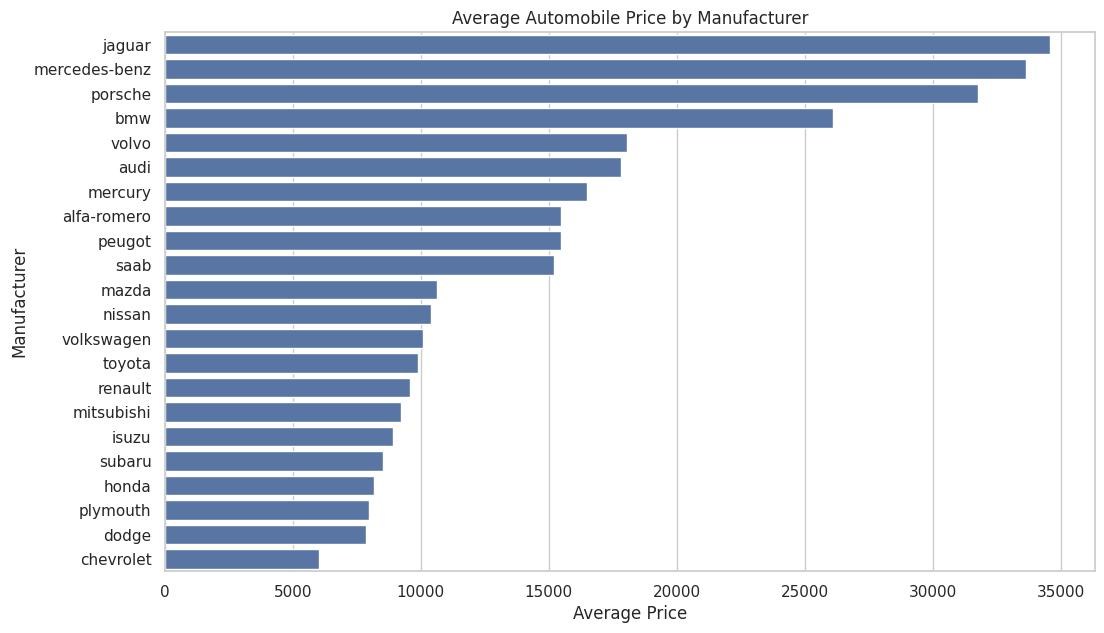

In [10]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=manufacturer_price,
    x="average_price",
    y="make"
)

plt.title("Average Automobile Price by Manufacturer")
plt.xlabel("Average Price")
plt.ylabel("Manufacturer")
plt.show()

5.4 Identify the highest and lowest average-priced manufacturers

In [11]:
highest_price_manufacturer = manufacturer_price.iloc[0]

lowest_price_manufacturer = manufacturer_price.iloc[-1]

print("Highest Average-Priced Manufacturer:")
display(highest_price_manufacturer)

print("\nLowest Average-Priced Manufacturer:")
display(lowest_price_manufacturer)

Highest Average-Priced Manufacturer:


,7
make,jaguar
vehicle_count,3
average_price,34600.0
median_price,35550.0
minimum_price,32250.0
maximum_price,36000.0



Lowest Average-Priced Manufacturer:


,3
make,chevrolet
vehicle_count,3
average_price,6007.0
median_price,6295.0
minimum_price,5151.0
maximum_price,6575.0


6. Engine size vs automobile price

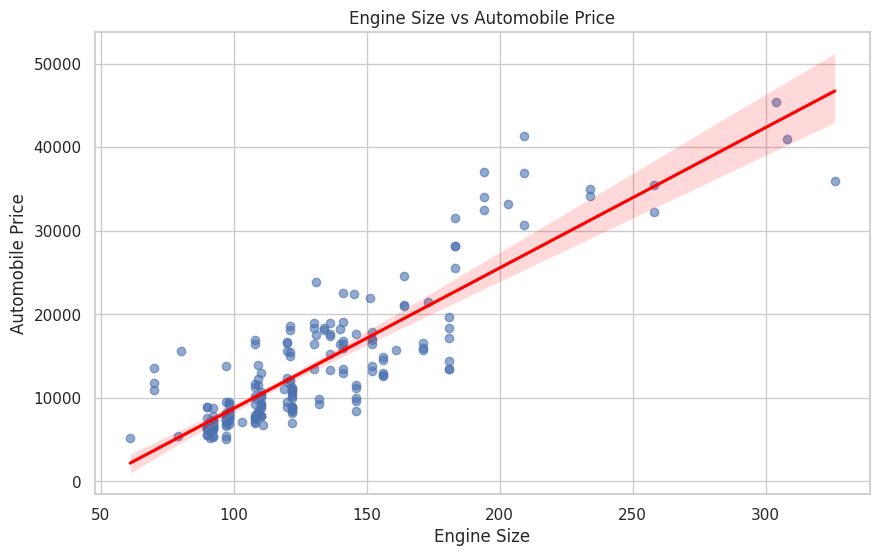

In [12]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="engine_size",
    y="price",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Engine Size vs Automobile Price")
plt.xlabel("Engine Size")
plt.ylabel("Automobile Price")
plt.show()

In [13]:
engine_price_correlation = df[
    ["engine_size", "price"]
].corr().iloc[0, 1]

print(
    "Correlation between engine size and price:",
    round(engine_price_correlation, 3)
)

Correlation between engine size and price: 0.874


7. Horsepower vs automobile price

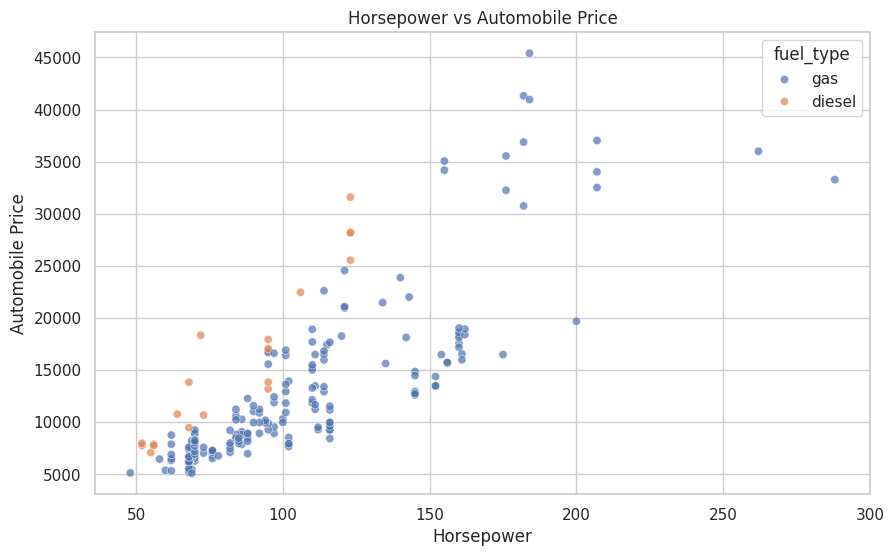

In [14]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="horsepower",
    y="price",
    hue="fuel_type" if "fuel_type" in df.columns else None,
    alpha=0.7
)

plt.title("Horsepower vs Automobile Price")
plt.xlabel("Horsepower")
plt.ylabel("Automobile Price")
plt.show()

In [15]:
horsepower_price_correlation = df[
    ["horsepower", "price"]
].corr().iloc[0, 1]

print(
    "Correlation between horsepower and price:",
    round(horsepower_price_correlation, 3)
)

Correlation between horsepower and price: 0.811


8. Fuel efficiency analysis

8.1 Average fuel efficiency

In [16]:
fuel_efficiency_summary = pd.DataFrame({
    "Fuel_Efficiency_Type": [
        "City MPG",
        "Highway MPG",
        "Combined MPG"
    ],
    "Average_MPG": [
        df["city_mpg"].mean(),
        df["highway_mpg"].mean(),
        df["combined_mpg"].mean()
    ],
    "Median_MPG": [
        df["city_mpg"].median(),
        df["highway_mpg"].median(),
        df["combined_mpg"].median()
    ]
})

display(fuel_efficiency_summary.round(2))

,Fuel_Efficiency_Type,Average_MPG,Median_MPG
0,City MPG,25.22,24.0
1,Highway MPG,30.75,30.0
2,Combined MPG,27.99,27.0


8.2 Compare city and highway MPG

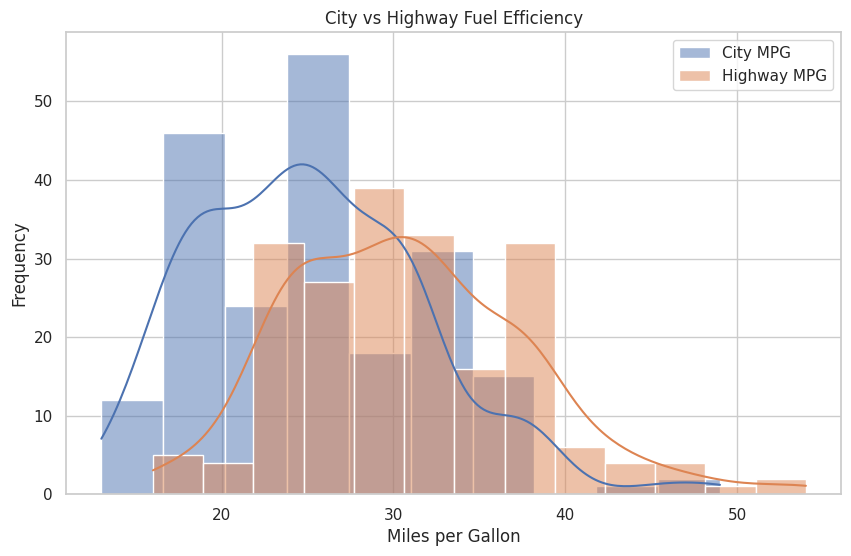

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["city_mpg"],
    label="City MPG",
    kde=True,
    alpha=0.5
)

sns.histplot(
    df["highway_mpg"],
    label="Highway MPG",
    kde=True,
    alpha=0.5
)

plt.title("City vs Highway Fuel Efficiency")
plt.xlabel("Miles per Gallon")
plt.ylabel("Frequency")
plt.legend()
plt.show()

8.3 Fuel efficiency by manufacturer

In [18]:
manufacturer_mpg = (
    df.groupby("make")
    .agg(
        vehicle_count=("make", "count"),
        average_city_mpg=("city_mpg", "mean"),
        average_highway_mpg=("highway_mpg", "mean"),
        average_combined_mpg=("combined_mpg", "mean")
    )
    .reset_index()
    .sort_values("average_combined_mpg", ascending=False)
)

display(manufacturer_mpg.round(2))

,make,vehicle_count,average_city_mpg,average_highway_mpg,average_combined_mpg
3,chevrolet,3,41.00,46.33,43.67
6,isuzu,4,31.00,36.00,33.50
5,honda,13,30.38,35.46,32.92
20,volkswagen,12,28.58,34.92,31.75
14,plymouth,7,28.14,34.14,31.14
4,dodge,9,28.00,34.11,31.06
19,toyota,32,27.50,32.91,30.20
12,nissan,18,27.00,32.94,29.97
8,mazda,17,25.71,31.94,28.82
18,subaru,12,26.33,30.75,28.54


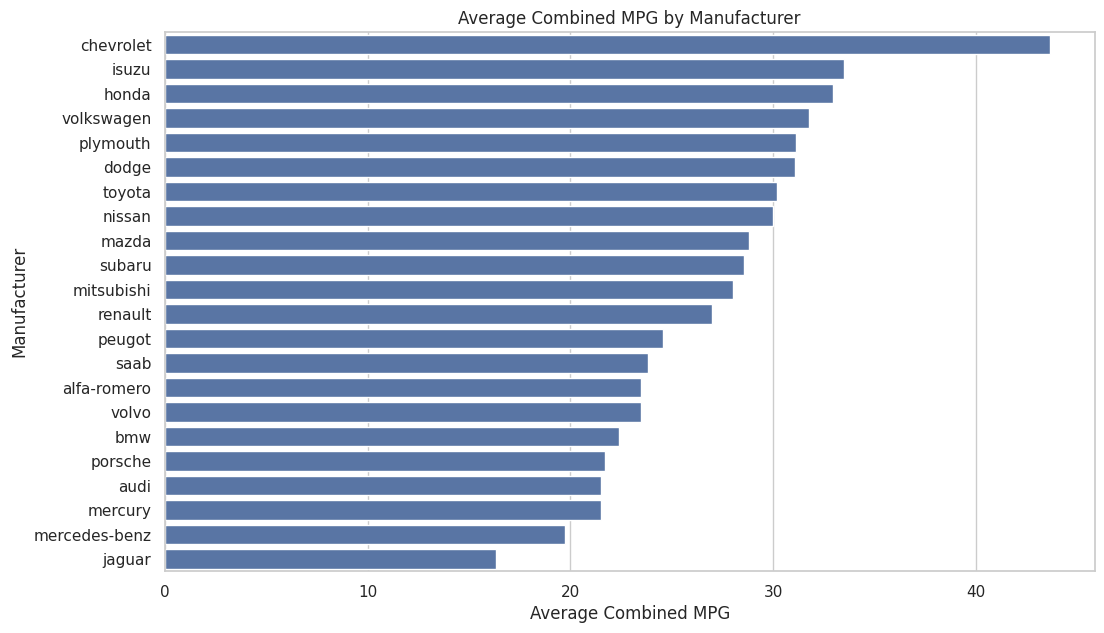

In [19]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=manufacturer_mpg,
    x="average_combined_mpg",
    y="make"
)

plt.title("Average Combined MPG by Manufacturer")
plt.xlabel("Average Combined MPG")
plt.ylabel("Manufacturer")
plt.show()

9. Curb weight vs fuel efficiency

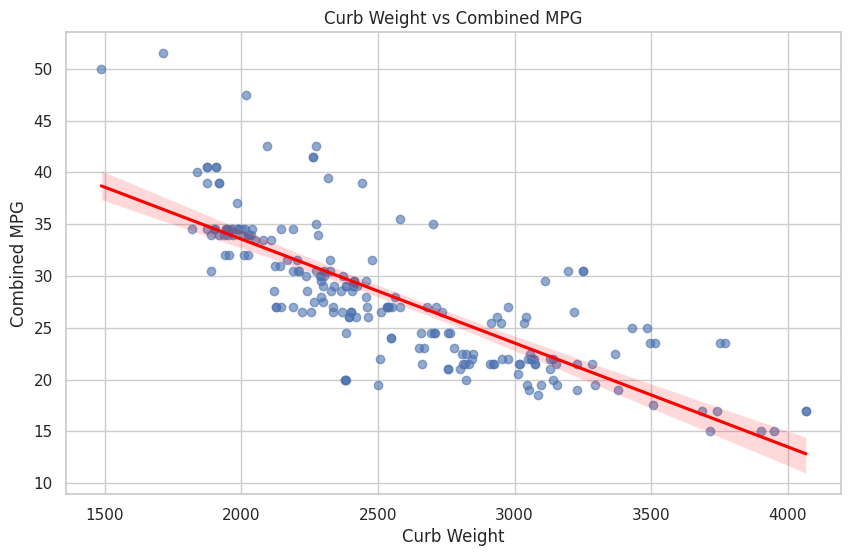

In [20]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="curb_weight",
    y="combined_mpg",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Curb Weight vs Combined MPG")
plt.xlabel("Curb Weight")
plt.ylabel("Combined MPG")
plt.show()

In [21]:
weight_mpg_correlation = df[
    ["curb_weight", "combined_mpg"]
].corr().iloc[0, 1]

print(
    "Correlation between curb weight and combined MPG:",
    round(weight_mpg_correlation, 3)
)

Correlation between curb weight and combined MPG: -0.784


10. Power-to-weight ratio analysis

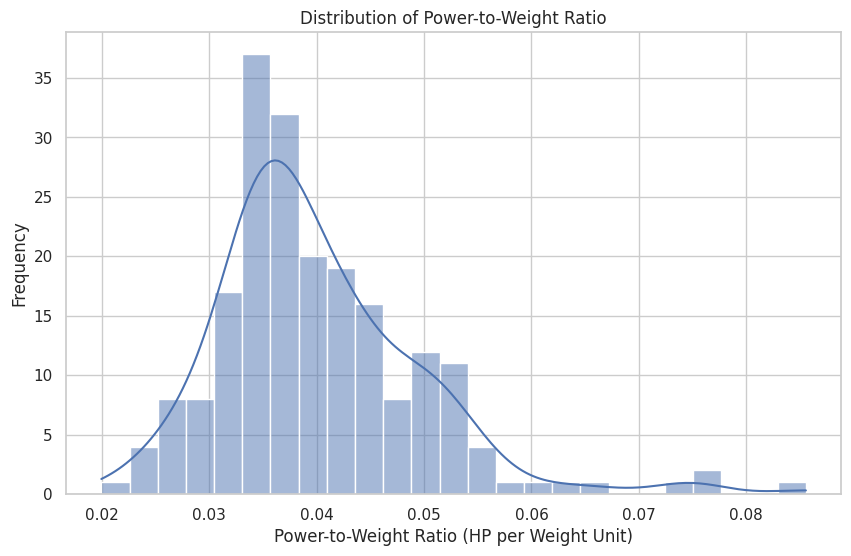

In [22]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="power_to_weight",
    bins=25,
    kde=True
)

plt.title("Distribution of Power-to-Weight Ratio")
plt.xlabel("Power-to-Weight Ratio (HP per Weight Unit)")
plt.ylabel("Frequency")
plt.show()

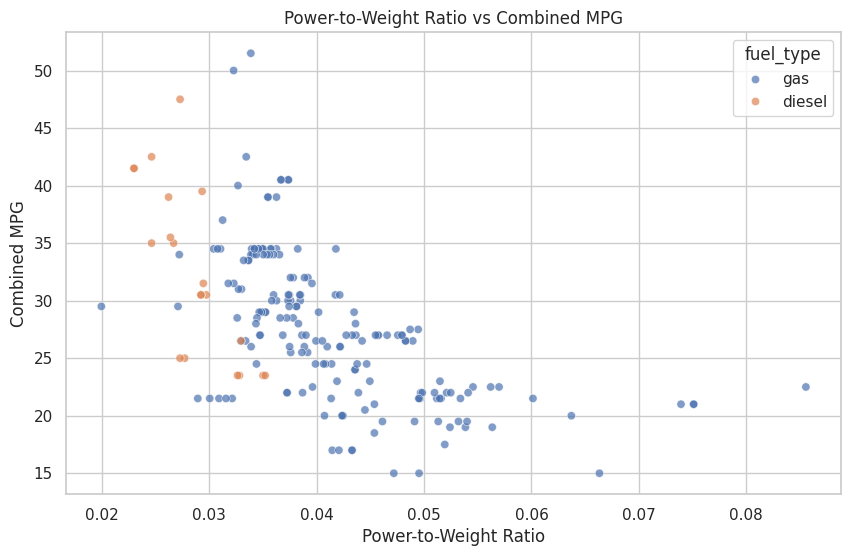

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="power_to_weight",
    y="combined_mpg",
    hue="fuel_type" if "fuel_type" in df.columns else None,
    alpha=0.7
)

plt.title("Power-to-Weight Ratio vs Combined MPG")
plt.xlabel("Power-to-Weight Ratio")
plt.ylabel("Combined MPG")
plt.show()

In [24]:
power_mpg_correlation = df[
    ["power_to_weight", "combined_mpg"]
].corr().iloc[0, 1]

print(
    "Correlation between power-to-weight ratio and combined MPG:",
    round(power_mpg_correlation, 3)
)

Correlation between power-to-weight ratio and combined MPG: -0.598


11. Automobile performance trade-off analysis

11.1 Price vs combined MPG

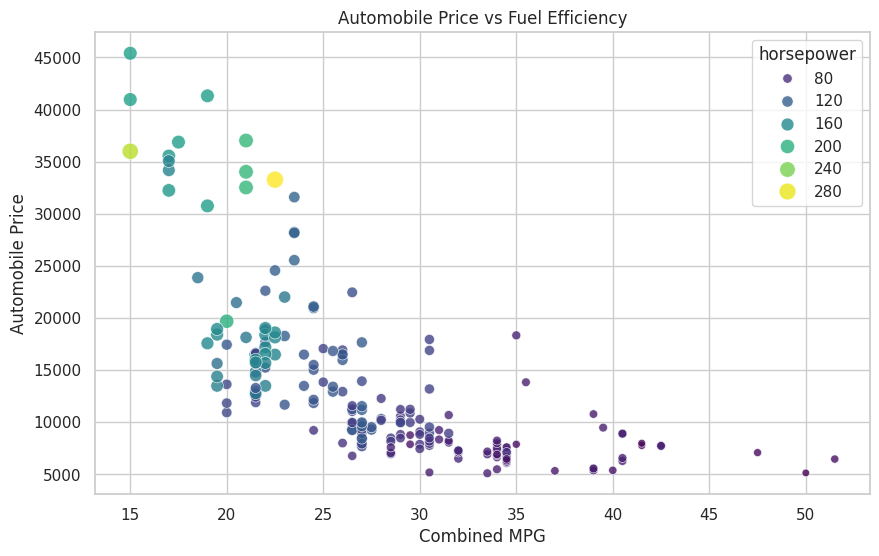

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="combined_mpg",
    y="price",
    hue="horsepower",
    palette="viridis",
    size="horsepower",
    sizes=(30, 150),
    alpha=0.8
)

plt.title("Automobile Price vs Fuel Efficiency")
plt.xlabel("Combined MPG")
plt.ylabel("Automobile Price")
plt.show()

11.2 Horsepower vs combined MPG

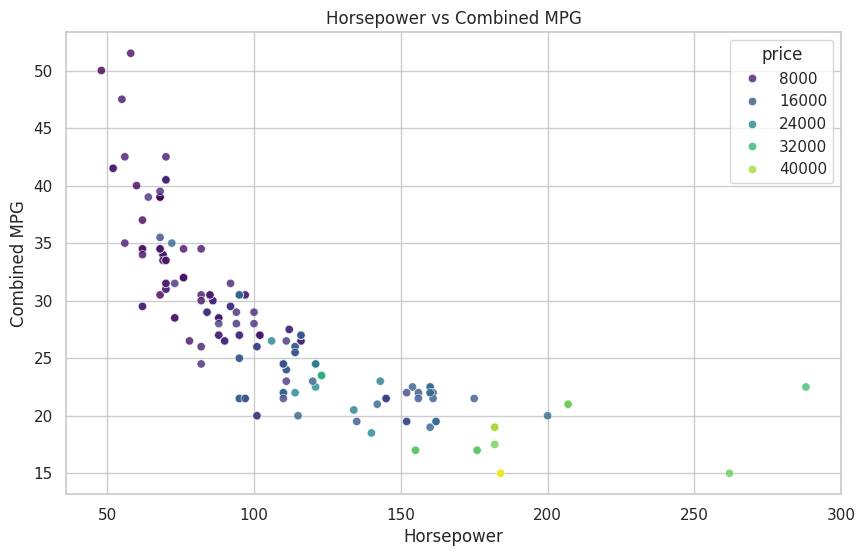

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="horsepower",
    y="combined_mpg",
    hue="price",
    palette="viridis",
    alpha=0.8
)

plt.title("Horsepower vs Combined MPG")
plt.xlabel("Horsepower")
plt.ylabel("Combined MPG")
plt.show()

11.3 Engine size vs fuel efficiency

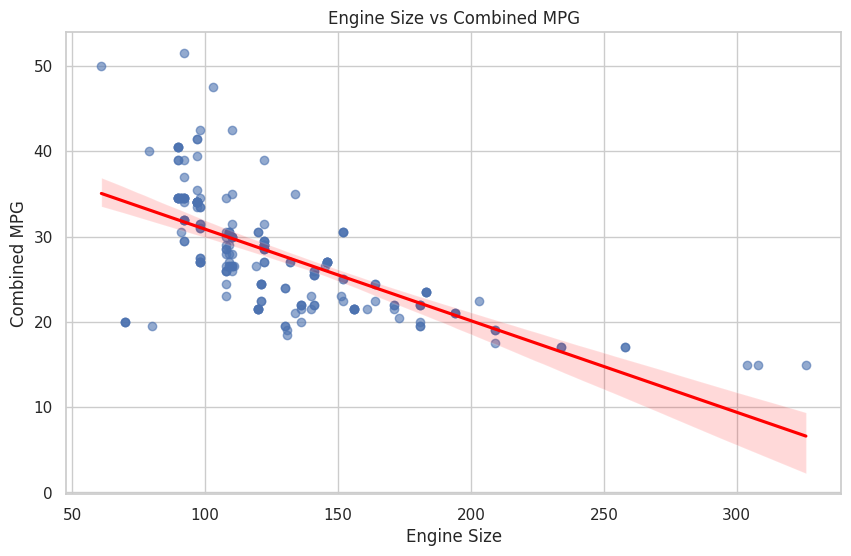

In [27]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="engine_size",
    y="combined_mpg",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Engine Size vs Combined MPG")
plt.xlabel("Engine Size")
plt.ylabel("Combined MPG")
plt.show()

11.4 Correlation analysis of price and performance

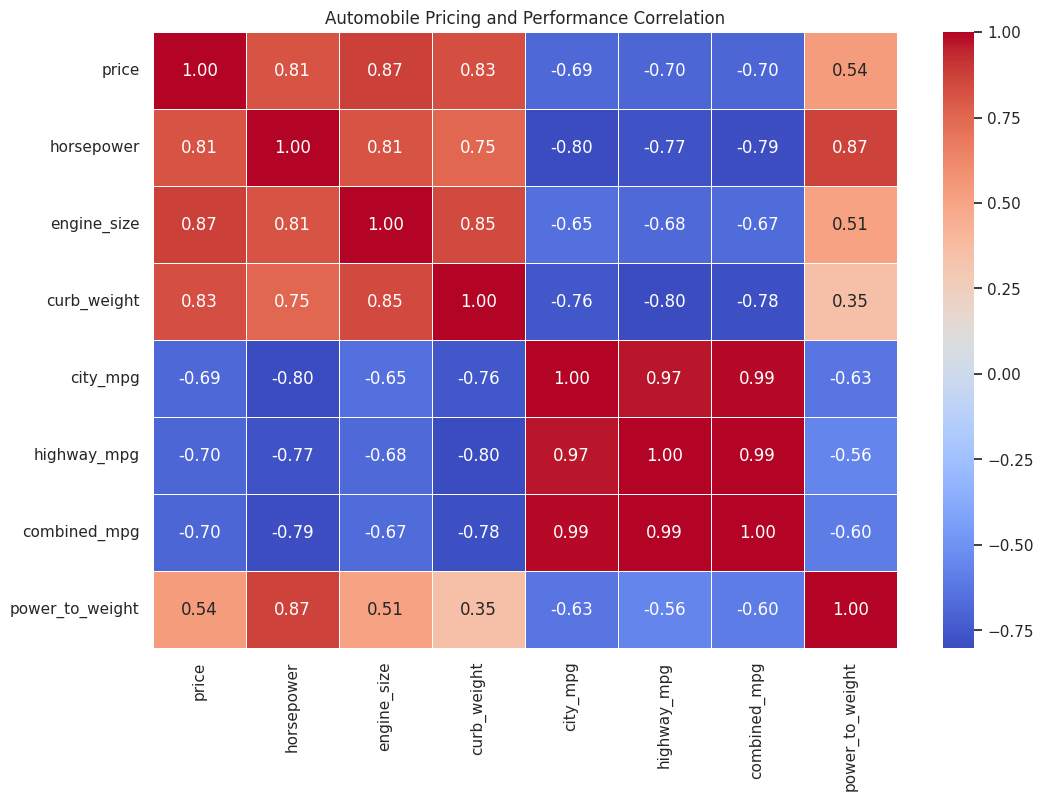

In [28]:
tradeoff_columns = [
    "price",
    "horsepower",
    "engine_size",
    "curb_weight",
    "city_mpg",
    "highway_mpg",
    "combined_mpg",
    "power_to_weight"
]

tradeoff_correlation = df[
    tradeoff_columns
].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    tradeoff_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Automobile Pricing and Performance Correlation")
plt.show()

12. Classify automobiles based on price

In [29]:
df["price_category"] = pd.qcut(
    df["price"],
    q=4,
    labels=[
        "Budget",
        "Mid-Range",
        "Premium",
        "Luxury"
    ],
    duplicates="drop"
)

price_category_summary = (
    df.groupby("price_category", observed=False)
    .agg(
        vehicle_count=("price", "count"),
        average_price=("price", "mean"),
        median_price=("price", "median"),
        average_horsepower=("horsepower", "mean"),
        average_combined_mpg=("combined_mpg", "mean")
    )
    .reset_index()
)

display(price_category_summary.round(2))

,price_category,vehicle_count,average_price,median_price,average_horsepower,average_combined_mpg
0,Budget,52,6699.58,6790.0,69.35,35.26
1,Mid-Range,51,8915.12,8916.5,87.57,29.96
2,Premium,51,13288.06,13200.0,113.86,24.67
3,Luxury,51,24364.39,20970.0,146.57,21.91


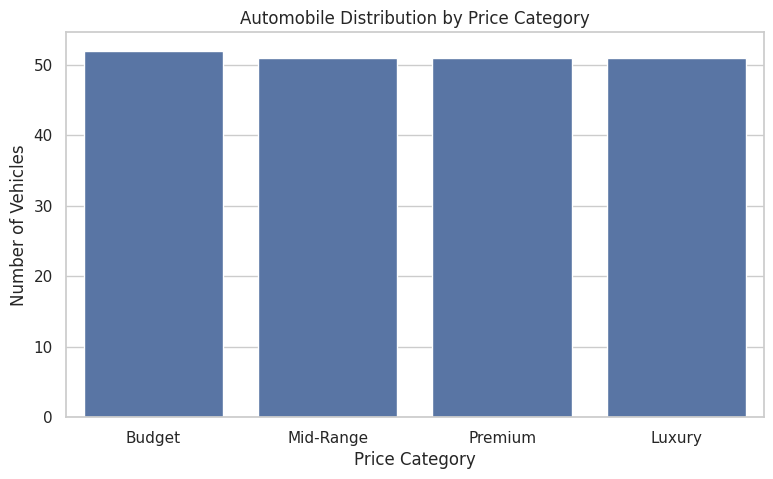

In [30]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="price_category",
    order=[
        "Budget",
        "Mid-Range",
        "Premium",
        "Luxury"
    ]
)

plt.title("Automobile Distribution by Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Vehicles")
plt.show()

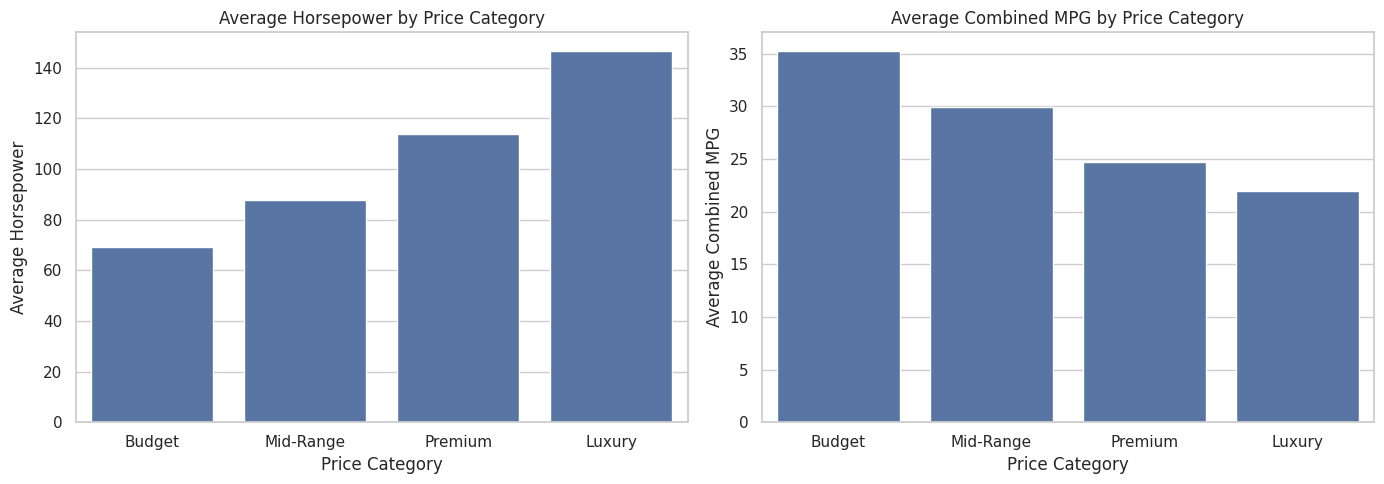

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=price_category_summary,
    x="price_category",
    y="average_horsepower",
    ax=axes[0]
)

axes[0].set_title("Average Horsepower by Price Category")
axes[0].set_xlabel("Price Category")
axes[0].set_ylabel("Average Horsepower")

sns.barplot(
    data=price_category_summary,
    x="price_category",
    y="average_combined_mpg",
    ax=axes[1]
)

axes[1].set_title("Average Combined MPG by Price Category")
axes[1].set_xlabel("Price Category")
axes[1].set_ylabel("Average Combined MPG")

plt.tight_layout()
plt.show()

13. Identify automobile performance profiles

In [32]:
performance_summary = (
    df.groupby("make")
    .agg(
        vehicle_count=("make", "count"),
        average_price=("price", "mean"),
        average_horsepower=("horsepower", "mean"),
        average_engine_size=("engine_size", "mean"),
        average_combined_mpg=("combined_mpg", "mean"),
        average_power_to_weight=("power_to_weight", "mean")
    )
    .reset_index()
)

display(
    performance_summary.sort_values(
        "average_combined_mpg",
        ascending=False
    ).round(2)
)

,make,vehicle_count,average_price,average_horsepower,average_engine_size,average_combined_mpg,average_power_to_weight
3,chevrolet,3,6007.00,62.67,80.33,43.67,0.04
6,isuzu,4,8916.50,77.00,102.50,33.50,0.04
5,honda,13,8184.69,80.23,99.31,32.92,0.04
20,volkswagen,12,10077.50,81.08,107.25,31.75,0.03
14,plymouth,7,7963.43,86.71,106.29,31.14,0.04
4,dodge,9,7875.44,86.33,102.67,31.06,0.04
19,toyota,32,9885.81,92.78,118.81,30.20,0.04
12,nissan,18,10415.67,102.56,127.89,29.97,0.04
8,mazda,17,10652.88,85.53,103.00,28.82,0.04
18,subaru,12,8541.25,86.25,107.08,28.54,0.04


In [33]:
highest_mpg = performance_summary.loc[
    performance_summary["average_combined_mpg"].idxmax()
]

lowest_mpg = performance_summary.loc[
    performance_summary["average_combined_mpg"].idxmin()
]

print("Highest Average Combined MPG:")
display(highest_mpg)

print("\nLowest Average Combined MPG:")
display(lowest_mpg)

Highest Average Combined MPG:


,3
make,chevrolet
vehicle_count,3
average_price,6007.0
average_horsepower,62.666667
average_engine_size,80.333333
average_combined_mpg,43.666667
average_power_to_weight,0.035427



Lowest Average Combined MPG:


,7
make,jaguar
vehicle_count,3
average_price,34600.0
average_horsepower,204.666667
average_engine_size,280.666667
average_combined_mpg,16.333333
average_power_to_weight,0.050967


14. Generate automobile pricing and performance insights

In [34]:
print("AUTOMOBILE PRICING AND PERFORMANCE REPORT")
print("------------------------------------------")

print(
    f"1. Total automobile records analyzed: {len(df)}"
)

print(
    f"2. Average automobile price: {df['price'].mean():,.2f}"
)

print(
    f"3. Median automobile price: {df['price'].median():,.2f}"
)

print(
    f"4. Average horsepower: {df['horsepower'].mean():.2f}"
)

print(
    f"5. Average combined MPG: {df['combined_mpg'].mean():.2f}"
)

print(
    f"6. Correlation between engine size and price: "
    f"{engine_price_correlation:.3f}"
)

print(
    f"7. Correlation between horsepower and price: "
    f"{horsepower_price_correlation:.3f}"
)

print(
    f"8. Correlation between curb weight and combined MPG: "
    f"{weight_mpg_correlation:.3f}"
)

print(
    f"9. Manufacturer with highest average price: "
    f"{highest_price_manufacturer['make']}"
)

print(
    f"10. Manufacturer with highest average combined MPG: "
    f"{highest_mpg['make']}"
)

print(
    "11. Price categories were created using quartiles "
    "of the observed automobile prices."
)

print(
    "12. Performance trade-offs were examined using "
    "price, horsepower, engine size, vehicle weight "
    "and fuel efficiency."
)

AUTOMOBILE PRICING AND PERFORMANCE REPORT
------------------------------------------
1. Total automobile records analyzed: 205
2. Average automobile price: 13,284.51
3. Median automobile price: 10,295.00
4. Average horsepower: 104.17
5. Average combined MPG: 27.99
6. Correlation between engine size and price: 0.874
7. Correlation between horsepower and price: 0.811
8. Correlation between curb weight and combined MPG: -0.784
9. Manufacturer with highest average price: jaguar
10. Manufacturer with highest average combined MPG: chevrolet
11. Price categories were created using quartiles of the observed automobile prices.
12. Performance trade-offs were examined using price, horsepower, engine size, vehicle weight and fuel efficiency.


15. Export all Week 12 reports

In [35]:
os.makedirs("week12_reports", exist_ok=True)

# Automobile analysis dataset
df.to_csv(
    "week12_reports/automobile_week12_analysis.csv",
    index=False
)

# Manufacturer price analysis
manufacturer_price.to_csv(
    "week12_reports/manufacturer_price_summary.csv",
    index=False
)

# Manufacturer fuel-efficiency analysis
manufacturer_mpg.to_csv(
    "week12_reports/manufacturer_fuel_efficiency_summary.csv",
    index=False
)

# Fuel-efficiency statistics
fuel_efficiency_summary.to_csv(
    "week12_reports/fuel_efficiency_summary.csv",
    index=False
)

# Price category analysis
price_category_summary.to_csv(
    "week12_reports/price_category_summary.csv",
    index=False
)

# Manufacturer performance analysis
performance_summary.to_csv(
    "week12_reports/manufacturer_performance_summary.csv",
    index=False
)

# Correlation matrix
tradeoff_correlation.to_csv(
    "week12_reports/automobile_tradeoff_correlation.csv"
)

print("All Week 12 reports exported successfully!")

All Week 12 reports exported successfully!
